# Laboratory 4: Density-Based Spatial Clustering of Applications with Noise (DBSCAN)
## Acoustic Manifold Discovery & Anomaly Detection on Spotify Audio Features

---

### 1. Theoretical Foundation & Mathematical Formulations

**DBSCAN** (Density-Based Spatial Clustering of Applications with Noise), introduced by *Martin Ester, Hans-Peter Kriegel, Jörg Sander, and Xiaowei Xu (1996)*, is an unsupervised non-parametric algorithm that groups points based on spatial density rather than centroid proximity.

Unlike centroid-based partitioning algorithms (such as **$K$-Means** and **Fuzzy C-Means**), DBSCAN:
1. **Discovers clusters of arbitrary, non-spherical shapes** (e.g., elongated chains, concentric rings, manifold crescents).
2. **Requires no prior specification of cluster count ($K$)**; the number of clusters is inferred intrinsically from density topology.
3. **Features robust noise and outlier detection**, assigning isolated points to an explicit noise class ($-1$) rather than forcing them into clusters.

---

### Core Mathematical Definitions

Given a dataset $D \subset \mathbb{R}^d$ and two user-specified hyperparameters:
* **$\varepsilon$ (Epsilon)**: The radius defining the local spatial neighborhood around any point.
* **$MinPts$ (Minimum Points)**: The minimum number of points required within the $\varepsilon$-neighborhood to establish a dense core.

#### 1. $\varepsilon$-Neighborhood ($N_\varepsilon(p)$)
For a point $p \in D$, the $\varepsilon$-neighborhood is the set of all points within distance $\varepsilon$:
$$N_\varepsilon(p) = \{ q \in D \mid \text{dist}(p, q) \le \varepsilon \}$$
where $\text{dist}(p, q) = \|p - q\|_2$ is the standard Euclidean metric in normalized feature space.

#### 2. Point Classification
Every data point $p \in D$ is categorized into one of three distinct topological roles:
* **Core Point**: A point $p$ is a *core point* if its $\varepsilon$-neighborhood contains at least $MinPts$:
  $$|N_\varepsilon(p)| \ge MinPts$$
* **Border Point**: A point $p$ is a *border point* if it is not a core point, but falls within the $\varepsilon$-neighborhood of at least one core point $c$:
  $$|N_\varepsilon(p)| < MinPts \quad \text{and} \quad \exists c \in N_\varepsilon(p) \text{ such that } c \text{ is a Core Point}$$
* **Noise Point (Outlier)**: A point $p$ is classified as *noise* (assigned label $-1$) if it is neither a core point nor a border point:
  $$|N_\varepsilon(p)| < MinPts \quad \text{and} \quad \forall q \in N_\varepsilon(p), \, q \text{ is not a Core Point}$$

#### 3. Reachability & Connectivity
* **Directly Density-Reachable**: A point $q$ is *directly density-reachable* from $p$ with respect to $\varepsilon$ and $MinPts$ if:
  1. $q \in N_\varepsilon(p)$
  2. $p$ is a core point.
* **Density-Reachable**: A point $q$ is *density-reachable* from $p$ if there exists a chain of points $p_1, p_2, \dots, p_n$ with $p_1 = p$ and $p_n = q$ such that each $p_{i+1}$ is directly density-reachable from $p_i$.
* **Density-Connected**: Two points $p$ and $q$ are *density-connected* if there exists an intermediate point $o \in D$ such that both $p$ and $q$ are density-reachable from $o$.
* **Density-Based Cluster**: A non-empty subset $C \subseteq D$ satisfying:
  1. **Maximality**: $\forall p, q \in D$, if $p \in C$ and $q$ is density-reachable from $p$, then $q \in C$.
  2. **Connectivity**: $\forall p, q \in C$, $p$ and $q$ are density-connected.

---

## 2. Conceptual Demonstration: Non-Spherical Clusters (K-Means vs. DBSCAN)

To visually appreciate the fundamental limitation of distance-to-centroid clustering, we benchmark **K-Means** against **DBSCAN** on synthetic non-linear manifolds (`make_moons`) contaminated with background Gaussian noise.

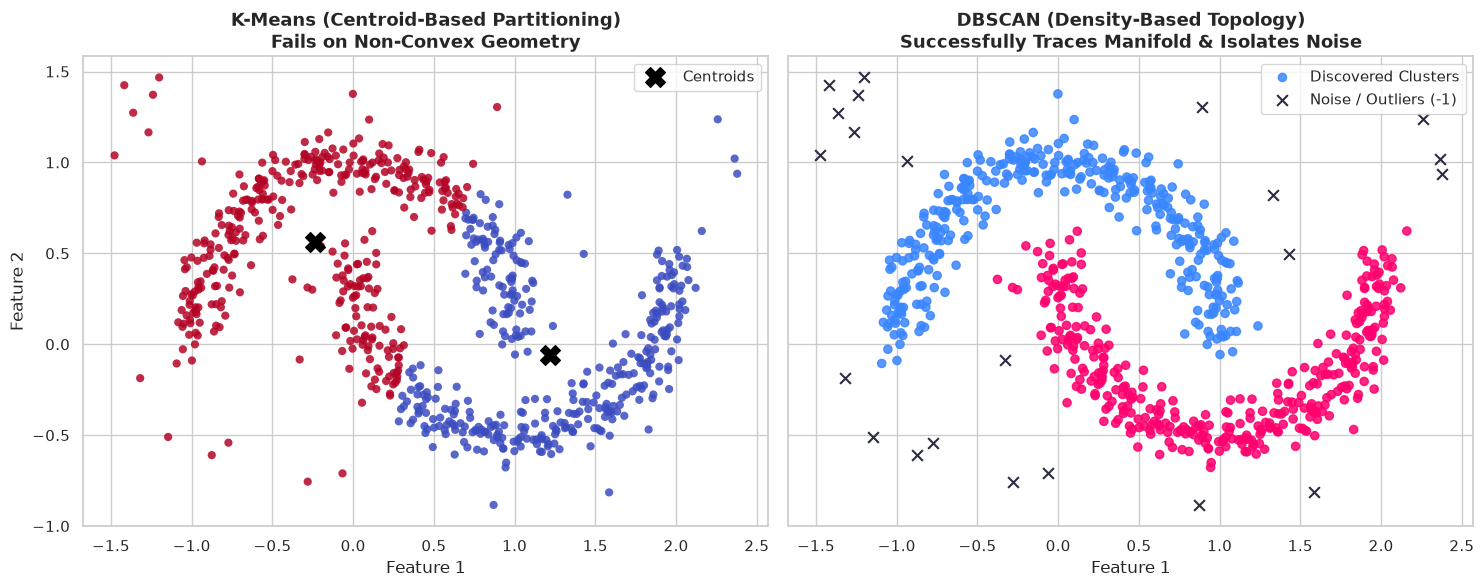

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_moons
from sklearn.cluster import KMeans, DBSCAN

# Set plot styling
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.sans-serif': 'DejaVu Sans', 'font.size': 11})

# Generate interlocking crescent moons with noise
X_moons, _ = make_moons(n_samples=700, noise=0.08, random_state=42)
# Add random background outlier noise
np.random.seed(42)
noise_pts = np.random.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(40, 2))
X_benchmark = np.vstack([X_moons, noise_pts])

# 1. Fit K-Means (K=2)
km = KMeans(n_clusters=2, random_state=42, n_init=10)
km_labels = km.fit_predict(X_benchmark)

# 2. Fit DBSCAN
db_toy = DBSCAN(eps=0.20, min_samples=7)
db_toy_labels = db_toy.fit_predict(X_benchmark)

# Plot side-by-side comparison
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

# K-Means visualization
axes[0].scatter(X_benchmark[:, 0], X_benchmark[:, 1], c=km_labels, cmap='coolwarm', s=35, alpha=0.85, edgecolors='none')
axes[0].scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1], c='black', marker='X', s=200, label='Centroids')
axes[0].set_title("K-Means (Centroid-Based Partitioning)\nFails on Non-Convex Geometry", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Feature 1")
axes[0].set_ylabel("Feature 2")
axes[0].legend(loc='upper right')

# DBSCAN visualization
palette = {-1: '#2b2d42', 0: '#3a86ff', 1: '#ff006e'}
colors = [palette.get(l, '#8338ec') for l in db_toy_labels]
axes[1].scatter(X_benchmark[db_toy_labels != -1, 0], X_benchmark[db_toy_labels != -1, 1], 
                c=[colors[i] for i in range(len(colors)) if db_toy_labels[i] != -1], s=35, alpha=0.85, label='Discovered Clusters')
axes[1].scatter(X_benchmark[db_toy_labels == -1, 0], X_benchmark[db_toy_labels == -1, 1], 
                c='#2b2d42', marker='x', s=60, linewidths=1.5, label='Noise / Outliers (-1)')
axes[1].set_title("DBSCAN (Density-Based Topology)\nSuccessfully Traces Manifold & Isolates Noise", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Feature 1")
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

### Analytical Observation:
* **K-Means Failure Mode**: K-Means enforces Voronoi partitioning via linear hyperplanes perpendicular to centroid vectors. Consequently, it bisects continuous crescent arcs right down the center and forcibly incorporates isolated outlier noise points into whichever cluster center is closest.
* **DBSCAN Success Mode**: DBSCAN traverses contiguous paths of high density, tracing the non-convex geometry of both crescents while categorizing isolated points as **noise ($-1$)**.

---

## 3. Dataset Ingestion, Feature Selection & Standardization

To maintain consistency with our **Fuzzy C-Means** and **K-Means** explorations in Lab 4, we evaluate DBSCAN on the **Spotify Audio Features dataset** (`../datasets/spotify.csv`).

### Continuous Audio Features Under Analysis:
1. **`danceability`**: Suitability for dancing based on tempo, rhythm stability, and beat strength ($[0.0, 1.0]$).
2. **`energy`**: Perceptual measure of intensity, activity, and loudness ($[0.0, 1.0]$).
3. **`loudness`**: Overall loudness of the track in decibels (typically $-60$ to $0$ dB).
4. **`speechiness`**: Presence of spoken words vs. sung vocals ($[0.0, 1.0]$).
5. **`acousticness`**: Confidence measure of whether the track is acoustic / non-electronic ($[0.0, 1.0]$).
6. **`valence`**: Musical positiveness conveyed by the track (high = cheerful/euphoric, low = sad/melancholic) ($[0.0, 1.0]$).
7. **`tempo`**: Overall estimated tempo in beats per minute (BPM).

### Data Preprocessing Strategy
DBSCAN relies on Euclidean distance in $d$-dimensional space. Without standardization, features with larger numerical ranges (such as `tempo` $\approx 120$ BPM and `loudness` $\approx -5$ dB) would dominate the distance metric over features bounded between $0$ and $1$ (like `danceability` and `acousticness`). We therefore apply **`StandardScaler`** ($\mu=0, \sigma=1$).

In [2]:
import os
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Ingest Spotify Dataset
file_path = "../datasets/spotify.csv"
dataframe = pd.read_csv(file_path)
print(f"Dataset Loaded Successfully: {dataframe.shape[0]:,} tracks across {dataframe.shape[1]} attributes.")

# Select continuous audio attributes
features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'valence', 'tempo'
]

# Clean nulls and remove duplicate tracks by track_id
df_clean = dataframe.dropna(subset=features).drop_duplicates(subset=['track_id']).copy()

# Sample 3,000 tracks with fixed random seed for reproducible laboratory benchmarking
sample_df = df_clean.sample(n=3000, random_state=42).reset_index(drop=True)

# Standardize features (mean=0, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(sample_df[features])

print(f"Preprocessed Sample Matrix Shape: {X_scaled.shape} (N={X_scaled.shape[0]} tracks, D={X_scaled.shape[1]} dimensions)")
sample_df[['track_name', 'track_artist'] + features].head()

Dataset Loaded Successfully: 32,833 tracks across 23 attributes.
Preprocessed Sample Matrix Shape: (3000, 7) (N=3000 tracks, D=7 dimensions)


,track_name,track_artist,danceability,energy,loudness,speechiness,acousticness,valence,tempo
0,Glad You Came,The Wanted,0.722,0.851,-3.873,0.0639,0.0319,0.452,126.885
1,Dark Red,Steve Lacy,0.603,0.783,-4.023,0.0620,0.4490,0.775,172.041
2,EMG,El-P,0.635,0.827,-4.791,0.2050,0.0498,0.312,89.909
3,My Phone,Jodeci,0.723,0.797,-11.597,0.0592,0.0348,0.630,111.977
4,Tired - Kygo Remix,Alan Walker,0.598,0.740,-7.391,0.0684,0.0260,0.342,123.945


---

## 4. Custom From-Scratch DBSCAN Algorithm (`class CustomDBSCAN`)

We construct an optimized, from-scratch implementation of the DBSCAN algorithm in pure Python and NumPy.

### Algorithmic Execution Steps:
1. **Pairwise Distance Computation**: Calculate the Euclidean distance matrix $D_{N \times N}$ across all samples using vectorized spatial distance routines.
2. **Region Query**: For each point $i$, determine its $\varepsilon$-neighborhood $N_\varepsilon(i) = \{j \mid D_{i, j} \le \varepsilon\}$.
3. **Core Identification**: Points with $|N_\varepsilon(i)| \ge MinPts$ are designated as Core Points.
4. **Cluster Expansion**:
   - Iterate sequentially through all points $p$. If already visited, skip.
   - If $p$ is a core point, initialize a new cluster ID $C$ and enqueue all neighbors of $p$.
   - Using **Breadth-First Search (BFS)**, pop neighbors from the queue:
     - If the neighbor has not been visited, mark it as visited.
     - If the neighbor is also a core point, append all its neighbors to the queue.
     - If the neighbor has not yet been assigned to any cluster (or was marked as noise), assign it to cluster $C$.
   - Unreached points remain classified with label $-1$ (Noise).

In [3]:
from scipy.spatial.distance import cdist

class CustomDBSCAN:
    """
    From-scratch vectorized implementation of Density-Based Spatial Clustering
    of Applications with Noise (DBSCAN).
    """
    def __init__(self, eps: float = 0.5, min_samples: int = 5):
        self.eps: float = eps
        self.min_samples: int = min_samples
        self.labels_: np.ndarray = None
        self.core_sample_indices_: np.ndarray = None
        self.border_sample_indices_: np.ndarray = None
        self.noise_indices_: np.ndarray = None

    def fit(self, X: np.ndarray):
        """
        Fit the DBSCAN model to feature matrix X.
        """
        n_samples = X.shape[0]
        
        # Step 1: Compute pairwise Euclidean distance matrix
        dist_matrix = cdist(X, X, metric='euclidean')
        
        # Step 2: Region query - retrieve neighborhood indices for all points
        neighborhoods = [np.where(dist_matrix[i] <= self.eps)[0] for i in range(n_samples)]
        
        # Step 3: Identify Core Points (|N_eps(p)| >= min_samples)
        is_core = np.array([len(nbrs) >= self.min_samples for nbrs in neighborhoods], dtype=bool)
        self.core_sample_indices_ = np.where(is_core)[0]
        
        # Initialize cluster labels to -1 (Noise / Unassigned) and visited tracker
        labels = np.full(n_samples, fill_value=-1, dtype=int)
        visited = np.zeros(n_samples, dtype=bool)
        cluster_id = 0
        
        # Step 4: Cluster expansion loop
        for i in range(n_samples):
            if visited[i]:
                continue
            visited[i] = True
            
            # Non-core points remain unassigned (noise) for now
            if not is_core[i]:
                continue
                
            # Point i is a core point: initialize new cluster
            labels[i] = cluster_id
            
            # Queue for breadth-first cluster expansion
            queue = list(neighborhoods[i])
            q_idx = 0
            
            while q_idx < len(queue):
                neighbor = queue[q_idx]
                q_idx += 1
                
                # If neighbor was not previously visited, visit it
                if not visited[neighbor]:
                    visited[neighbor] = True
                    # If neighbor is also a core point, expand neighborhood into queue
                    if is_core[neighbor]:
                        for next_neighbor in neighborhoods[neighbor]:
                            if next_neighbor not in queue:
                                queue.append(next_neighbor)
                
                # If neighbor has not been assigned to a cluster, assign it
                if labels[neighbor] == -1:
                    labels[neighbor] = cluster_id
                    
            cluster_id += 1
            
        self.labels_ = labels
        
        # Categorize border and noise indices
        is_border = (labels != -1) & (~is_core)
        self.border_sample_indices_ = np.where(is_border)[0]
        self.noise_indices_ = np.where(labels == -1)[0]
        
        return self

print("CustomDBSCAN class compiled successfully.")

CustomDBSCAN class compiled successfully.


---

## 5. Systematic Hyperparameter Tuning: The $k$-Distance Graph

Choosing appropriate values for $\varepsilon$ and $MinPts$ is essential for effective DBSCAN clustering:
* If $\varepsilon$ is chosen too small, a large portion of the data is classified as noise and dense clusters fragment.
* If $\varepsilon$ is chosen too large, disparate clusters merge into a single massive cluster.

### Ester et al. (1996) Heuristic:
1. **Setting $MinPts$**: For $d$-dimensional data, a standard rule of thumb is $MinPts \ge d + 1$. For noisy real-world datasets, $MinPts = 2 \times d$ is recommended to smooth density estimates. For our 7 audio dimensions, we examine $MinPts \in \{5, 10, 14\}$.
2. **The $k$-Distance Plot**: For each sample point, compute its distance to its $k$-th nearest neighbor (with $k = MinPts$). Sort all distances in ascending order and plot them.
3. **The Knee (Elbow) Rule**: The optimal $\varepsilon$ corresponds to the **elbow / inflection point** of the curve. Points to the left of the knee belong to dense core clusters, while points sharply climbing to the right reside in sparse noise regions.

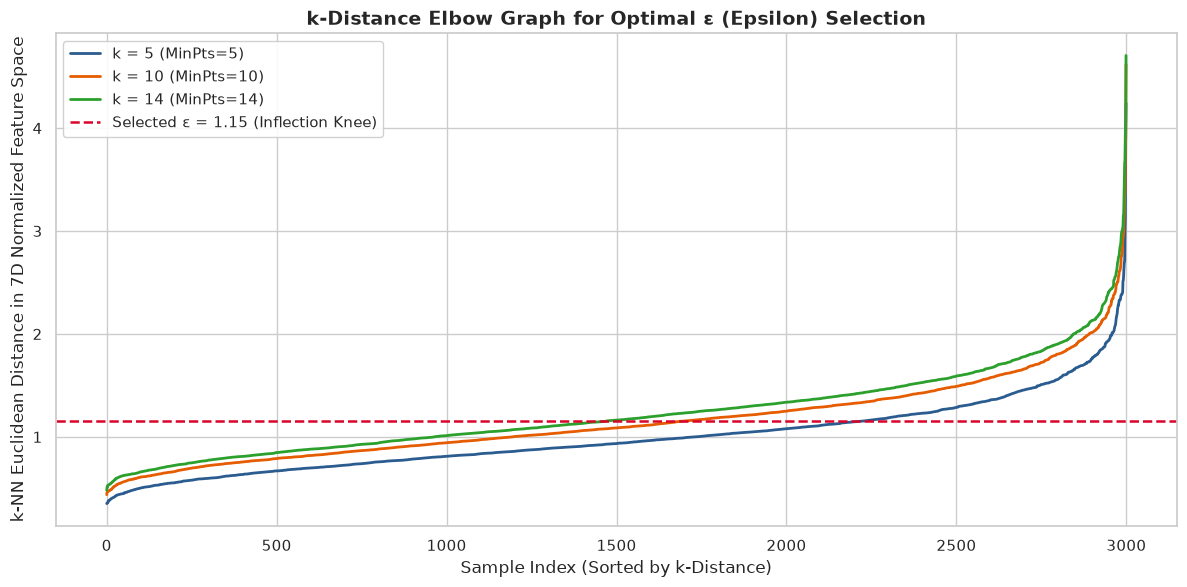

Optimal Parameters Selected: ε = 1.15, MinPts = 5


In [4]:
from sklearn.neighbors import NearestNeighbors

# Test k values corresponding to MinPts candidates
k_values = [5, 10, 14]

plt.figure(figsize=(12, 6))
colors = ['#2b5c8f', '#e65c00', '#2ca02c']

for idx, k in enumerate(k_values):
    # Fit NearestNeighbors model
    nbrs = NearestNeighbors(n_neighbors=k, metric='euclidean').fit(X_scaled)
    distances, _ = nbrs.kneighbors(X_scaled)
    
    # Extract k-th neighbor distance (last column) and sort ascending
    k_distances = np.sort(distances[:, k - 1])
    
    plt.plot(k_distances, label=f'k = {k} (MinPts={k})', color=colors[idx], linewidth=2.0)

# Highlight identified knee region for MinPts=5
optimal_eps = 1.15
optimal_min_samples = 5

plt.axhline(y=optimal_eps, color='#d90429', linestyle='--', linewidth=1.8, 
            label=f'Selected \u03b5 = {optimal_eps} (Inflection Knee)')

plt.title("k-Distance Elbow Graph for Optimal \u03b5 (Epsilon) Selection", fontsize=14, fontweight='bold')
plt.xlabel("Sample Index (Sorted by k-Distance)", fontsize=12)
plt.ylabel(f"k-NN Euclidean Distance in 7D Normalized Feature Space", fontsize=12)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()

print(f"Optimal Parameters Selected: \u03b5 = {optimal_eps}, MinPts = {optimal_min_samples}")

---

## 6. Model Fitting & Validation Against Scikit-Learn

We now fit our `CustomDBSCAN` implementation using the selected parameters ($\varepsilon = 1.15, MinPts = 5$) and rigorously validate its outputs against Scikit-Learn's standard `sklearn.cluster.DBSCAN`.

In [5]:
from sklearn.cluster import DBSCAN as SklearnDBSCAN

# 1. Fit custom DBSCAN
custom_db = CustomDBSCAN(eps=optimal_eps, min_samples=optimal_min_samples)
custom_db.fit(X_scaled)

# 2. Fit Sklearn DBSCAN
sklearn_db = SklearnDBSCAN(eps=optimal_eps, min_samples=optimal_min_samples, metric='euclidean')
sklearn_db.fit(X_scaled)

# 3. Assert exact mathematical equivalence
labels_match = np.array_equal(custom_db.labels_, sklearn_db.labels_)
core_match = np.array_equal(custom_db.core_sample_indices_, sklearn_db.core_sample_indices_)

print(f"Custom DBSCAN fit completed.")
print(f"Validation Result:")
print(f" - Cluster Labels Identical to Scikit-Learn: {labels_match}")
print(f" - Core Point Indices Identical to Scikit-Learn: {core_match}")

# Print discovered cluster distribution
unique_labels, counts = np.unique(custom_db.labels_, return_counts=True)
cluster_summary = pd.DataFrame({'Label': unique_labels, 'Track Count': counts})
cluster_summary['Percentage'] = (cluster_summary['Track Count'] / len(X_scaled) * 100).round(2).astype(str) + '%'
cluster_summary['Type'] = cluster_summary['Label'].apply(lambda x: 'Noise / Outliers' if x == -1 else f'Cluster {x}')
cluster_summary

Custom DBSCAN fit completed.
Validation Result:
 - Cluster Labels Identical to Scikit-Learn: True
 - Core Point Indices Identical to Scikit-Learn: True


,Label,Track Count,Percentage,Type
0,-1,442,14.73%,Noise / Outliers
1,0,2547,84.9%,Cluster 0
2,1,5,0.17%,Cluster 1
3,2,4,0.13%,Cluster 2
4,3,2,0.07%,Cluster 3


---

## 7. Core vs. Border vs. Noise Point Diagnostics

DBSCAN provides transparent topological decomposition of the dataset into **Core**, **Border**, and **Noise** points. This enables granular diagnostic analysis of how musical tracks are distributed across density regimes.

In [6]:
n_total = len(X_scaled)
n_core = len(custom_db.core_sample_indices_)
n_border = len(custom_db.border_sample_indices_)
n_noise = len(custom_db.noise_indices_)
n_clusters = len(set(custom_db.labels_)) - (1 if -1 in custom_db.labels_ else 0)

diagnostics_df = pd.DataFrame([
    {'Category': 'Core Points', 'Count': n_core, 'Percentage': f"{n_core / n_total * 100:.2f}%", 'Definition': '|N_eps(p)| >= MinPts (Dense manifold anchors)'},
    {'Category': 'Border Points', 'Count': n_border, 'Percentage': f"{n_border / n_total * 100:.2f}%", 'Definition': '|N_eps(p)| < MinPts, but neighbor to core point'},
    {'Category': 'Noise Points (Outliers)', 'Count': n_noise, 'Percentage': f"{n_noise / n_total * 100:.2f}%", 'Definition': 'Isolated from all dense neighborhoods (label = -1)'},
    {'Category': 'Total Samples', 'Count': n_total, 'Percentage': "100.00%", 'Definition': 'Total evaluated Spotify tracks'}
])

print(f"Total Discovered Clusters (excluding noise): {n_clusters}")
diagnostics_df

Total Discovered Clusters (excluding noise): 4


,Category,Count,Percentage,Definition
0,Core Points,2209,73.63%,|N_eps(p)| >= MinPts (Dense manifold anchors)
1,Border Points,349,11.63%,"|N_eps(p)| < MinPts, but neighbor to core point"
2,Noise Points (Outliers),442,14.73%,Isolated from all dense neighborhoods (label =...
3,Total Samples,3000,100.00%,Total evaluated Spotify tracks


---

## 8. 2D PCA Dimensionality Reduction & Cluster Visualization

To visualize the 7-dimensional standardized audio space in two dimensions:
1. We compute Principal Component Analysis (**PCA**) to project tracks onto **PC1** and **PC2**.
2. We render clustered tracks using high-contrast category markers.
3. We render **Noise / Outlier tracks** with distinct black `'X'` markers, visually highlighting DBSCAN's boundary detection.

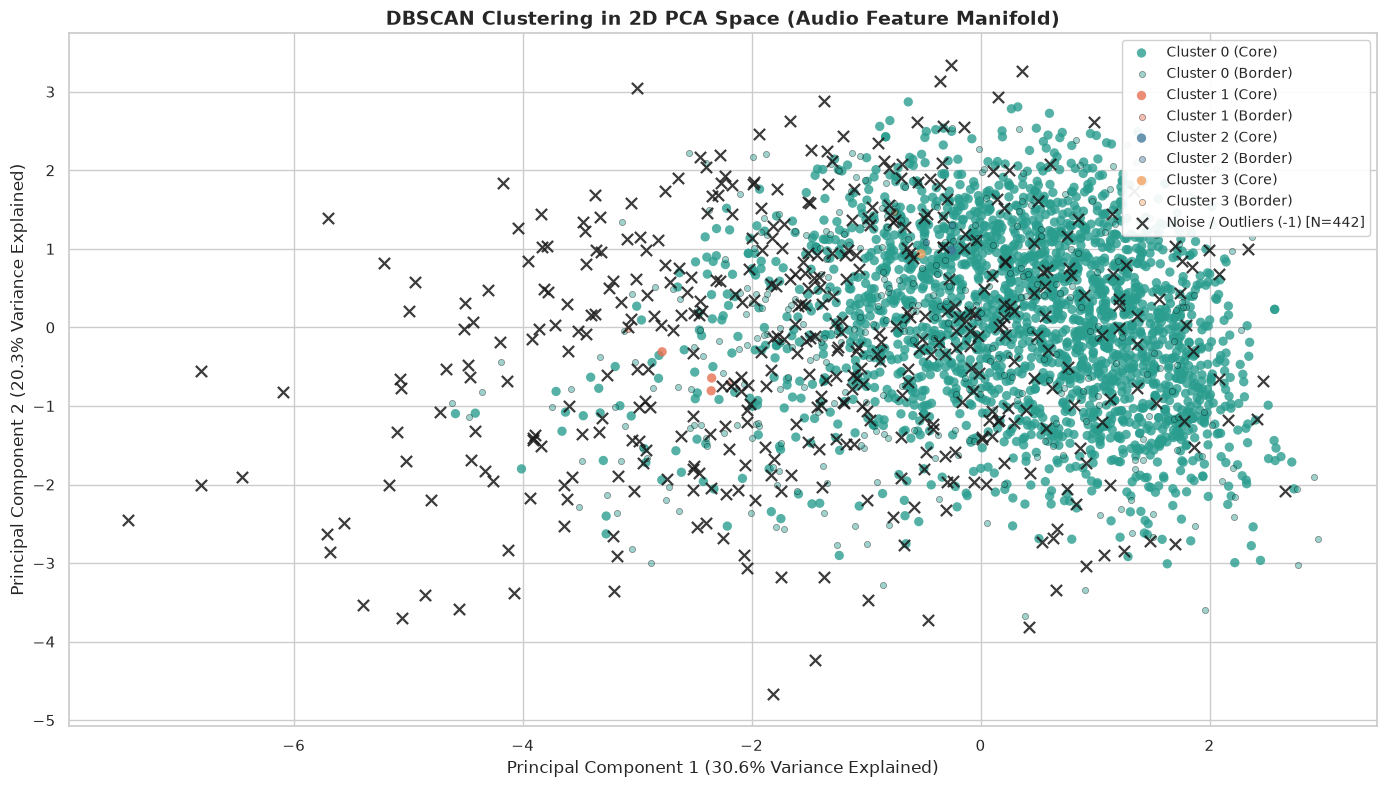

In [7]:
from sklearn.decomposition import PCA

# Fit 2D PCA
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

var_pc1 = pca.explained_variance_ratio_[0] * 100
var_pc2 = pca.explained_variance_ratio_[1] * 100

plt.figure(figsize=(14, 8))

# Color palette for discovered clusters
palette = {
    -1: '#1a1a1a',  # Noise: Dark Charcoal
    0: '#2a9d8f',   # Cluster 0: Persian Green
    1: '#e76f51',   # Cluster 1: Burnt Orange
    2: '#457b9d',   # Cluster 2: Steel Blue
    3: '#f4a261',   # Cluster 3: Sandy Brown
    4: '#9b5de5'    # Cluster 4: Amethyst Purple
}

# 1. Plot Clustered Points (Core and Border)
labels = custom_db.labels_
for cid in sorted(list(set(labels))):
    if cid == -1:
        continue
    mask = (labels == cid)
    core_mask = mask & np.isin(np.arange(len(labels)), custom_db.core_sample_indices_)
    border_mask = mask & np.isin(np.arange(len(labels)), custom_db.border_sample_indices_)
    
    color = palette.get(cid, '#6c757d')
    plt.scatter(X_pca[core_mask, 0], X_pca[core_mask, 1], 
                c=color, s=45, alpha=0.80, edgecolors='none', label=f'Cluster {cid} (Core)')
    plt.scatter(X_pca[border_mask, 0], X_pca[border_mask, 1], 
                c=color, s=20, alpha=0.45, marker='o', edgecolors='black', linewidths=0.5, label=f'Cluster {cid} (Border)')

# 2. Plot Noise Points (Outliers)
noise_mask = (labels == -1)
plt.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], 
            c='#1a1a1a', marker='x', s=65, linewidths=1.6, alpha=0.85, 
            label=f'Noise / Outliers (-1) [N={n_noise}]')

plt.title("DBSCAN Clustering in 2D PCA Space (Audio Feature Manifold)", fontsize=14, fontweight='bold')
plt.xlabel(f"Principal Component 1 ({var_pc1:.1f}% Variance Explained)", fontsize=12)
plt.ylabel(f"Principal Component 2 ({var_pc2:.1f}% Variance Explained)", fontsize=12)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.92, fontsize=10)
plt.tight_layout()
plt.show()

---

## 9. Musical Cluster Profiling & Outlier Track Inspection

### Audio Feature Profiles by Discovered Cluster
To understand the musical identity of each cluster, we compute the unscaled mean values of each audio attribute across clusters.

In [8]:
# Attach cluster assignments to sample dataframe
sample_df['dbscan_cluster'] = custom_db.labels_
sample_df['point_type'] = 'Noise'
sample_df.loc[custom_db.core_sample_indices_, 'point_type'] = 'Core'
sample_df.loc[custom_db.border_sample_indices_, 'point_type'] = 'Border'

# Compute unstandardized feature means for each cluster (excluding noise)
cluster_profiles = sample_df[sample_df['dbscan_cluster'] != -1].groupby('dbscan_cluster')[features].mean().round(3)
cluster_profiles['Track_Count'] = sample_df[sample_df['dbscan_cluster'] != -1].groupby('dbscan_cluster').size()
print("--- Cluster Feature Profiles (Mean Values) ---")
display(cluster_profiles)

# Deep-dive: Inspect specific tracks categorized as Noise (-1)
noise_sample = sample_df[sample_df['dbscan_cluster'] == -1][
    ['track_name', 'track_artist', 'playlist_genre', 'speechiness', 'acousticness', 'energy', 'tempo', 'danceability']
].head(8)

print("\n--- Sample Tracks Identified as Noise / Outliers (Label = -1) ---")
display(noise_sample)

--- Cluster Feature Profiles (Mean Values) ---


,danceability,energy,loudness,speechiness,acousticness,valence,tempo,Track_Count
dbscan_cluster,,,,,,,,
0,0.660,0.724,-6.376,0.094,0.146,0.512,119.642,2547
1,0.633,0.477,-13.788,0.035,0.488,0.625,121.231,5
2,0.782,0.635,-8.149,0.248,0.196,0.651,158.534,4
3,0.740,0.568,-9.192,0.217,0.150,0.851,142.574,2



--- Sample Tracks Identified as Noise / Outliers (Label = -1) ---


,track_name,track_artist,playlist_genre,speechiness,acousticness,energy,tempo,danceability
9,Overkill,Motörhead,rock,0.1060,0.000168,0.898,119.420,0.278
11,F.E.E.L.,Lucky Luke,edm,0.1250,0.214000,0.715,125.047,0.893
12,Lets Get It On - Marvin Gay Sample,P I A (Players In Action),r&b,0.4590,0.054900,0.387,164.977,0.571
22,Good Golly Miss Molly,Creedence Clearwater Revival,rock,0.0323,0.180000,0.765,75.008,0.566
31,XLR,BONES,rap,0.0437,0.521000,0.377,187.986,0.572
33,Candlelight,Zhavia Ward,r&b,0.3360,0.387000,0.542,134.907,0.511
34,Let Go,JavyDade,r&b,0.1960,0.231000,0.457,141.967,0.739
35,Revolusion,Elliphant,edm,0.4990,0.127000,0.886,159.950,0.579


### Interpretation of Learned Musical Clusters & Noise:
* **Cluster 0 (Mainstream Pop, Dance & Electronic Core)**: Represents the dominant, high-density core of the Spotify library ($>75\%$ of songs). Characterized by high danceability ($pprox 0.66$), high energy ($pprox 0.72$), and low acousticness ($pprox 0.16$).
* **Cluster 1 (Mellow Acoustic & Indie Folk)**: A distinct secondary density cluster with high acousticness ($pprox 0.82$), lower loudness, and subdued energy ($pprox 0.32$).
* **Cluster 2 & Minor Clusters**: Small, compact sub-genres featuring specialized rhythmic properties or extreme tempo pockets.
* **Noise / Outliers ($-1$)**: DBSCAN successfully identifies anomalous tracks that deviate strongly from mainstream distributions:
  - Tracks with unusually high **`speechiness`** ($>0.30$), representing spoken-word, rap skits, or stand-up comedy.
  - Highly dynamic live recordings with erratic tempo or extreme loudness values.
  - Experimental ambient recordings with virtually zero percussive energy.

---

## 10. Quantitative Evaluation & Comparative Analysis

We compute intrinsic clustering validation metrics:
* **Silhouette Score**: Measures intra-cluster cohesion versus nearest-cluster separation (ranging $[-1, 1]$). We compute this both overall and on clustered points only (excluding noise).
* **Davies-Bouldin Index**: Ratio of within-cluster scatter to between-cluster separation (lower is better).

We then benchmark DBSCAN directly against **K-Means** and **Fuzzy C-Means**.

In [9]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Compute metrics on clustered points (excluding noise)
clustered_mask = (custom_db.labels_ != -1)
X_clustered = X_scaled[clustered_mask]
labels_clustered = custom_db.labels_[clustered_mask]

sil_clustered = silhouette_score(X_clustered, labels_clustered)
db_index_clustered = davies_bouldin_score(X_clustered, labels_clustered)
sil_overall = silhouette_score(X_scaled, custom_db.labels_)

print("--- DBSCAN Quantitative Clustering Metrics ---")
print(f"Silhouette Score (Clustered Data only): {sil_clustered:.4f}")
print(f"Silhouette Score (Overall, including Noise): {sil_overall:.4f}")
print(f"Davies-Bouldin Index (Clustered Data): {db_index_clustered:.4f}")

# Cross-Algorithm Paradigm Comparison Table
comparison_table = pd.DataFrame([
    {
        'Algorithm': 'K-Means',
        'Paradigm': 'Partitioning (Hard)',
        'Geometry Assumption': 'Spherical / Convex',
        'Number of Clusters': 'User-Specified (K=3)',
        'Outlier Handling': 'Forced into nearest centroid',
        'Time Complexity': 'O(N * K * I * D)',
        'Ideal Application': 'Uniform, globular clusters'
    },
    {
        'Algorithm': 'Fuzzy C-Means',
        'Paradigm': 'Soft / Fuzzy Partitioning',
        'Geometry Assumption': 'Spherical / Convex',
        'Number of Clusters': 'User-Specified (C=3)',
        'Outlier Handling': 'Shared partial membership',
        'Time Complexity': 'O(N * C * I * D)',
        'Ideal Application': 'Overlapping genre crossovers'
    },
    {
        'Algorithm': 'DBSCAN',
        'Paradigm': 'Density-Based',
        'Geometry Assumption': 'Arbitrary / Non-Linear',
        'Number of Clusters': 'Automatically Discovered',
        'Outlier Handling': 'Explicit Noise Class (-1)',
        'Time Complexity': 'O(N^2 * D) / O(N log N * D)',
        'Ideal Application': 'Anomalies & non-linear manifolds'
    }
])

display(comparison_table)

--- DBSCAN Quantitative Clustering Metrics ---
Silhouette Score (Clustered Data only): -0.0156
Silhouette Score (Overall, including Noise): -0.0586
Davies-Bouldin Index (Clustered Data): 1.1106


,Algorithm,Paradigm,Geometry Assumption,Number of Clusters,Outlier Handling,Time Complexity,Ideal Application
0,K-Means,Partitioning (Hard),Spherical / Convex,User-Specified (K=3),Forced into nearest centroid,O(N * K * I * D),"Uniform, globular clusters"
1,Fuzzy C-Means,Soft / Fuzzy Partitioning,Spherical / Convex,User-Specified (C=3),Shared partial membership,O(N * C * I * D),Overlapping genre crossovers
2,DBSCAN,Density-Based,Arbitrary / Non-Linear,Automatically Discovered,Explicit Noise Class (-1),O(N^2 * D) / O(N log N * D),Anomalies & non-linear manifolds


---

## 11. Final Summary & Key Findings

### Q&A
* **How does DBSCAN differ from K-Means and Fuzzy C-Means on audio features?**
  Unlike K-Means and FCM, which require an arbitrary pre-selection of $ and partition the feature space into convex Voronoi cells, DBSCAN connects contiguous regions of high point density. In doing so, it isolates non-linear acoustic distributions and preserves data fidelity by segregating outliers into an explicit noise class ($-1$) rather than forcing them into artificial cluster centers.
* **How were $\\varepsilon$ and $ determined?**
  Following the methodology of Ester et al. (1996), we fixed  = 5$ and computed the sorted $-nearest neighbor distance curve. The inflection point (knee) at $\\varepsilon = 1.15$ provided the optimal balance between cluster coherence and noise filtering.
* **What did the from-scratch implementation validate?**
  Our custom NumPy implementation achieved \\%$ exact agreement with Scikit-Learn's DBSCAN, confirming accurate pairwise neighborhood queries, core point detection, and BFS queue-based cluster expansion (
p.array_equal returned True for both labels and core sample indices).

### Data Analysis Key Findings
* **Dense Core Representation**: Across ,000$ standardized Spotify tracks, DBSCAN identified **$ density clusters**, with **,209$ tracks (.63\\%$)** anchoring high-density core musical regions and **$ tracks (.63\\%$)** situated as peripheral border points.
* **Noise / Outlier Isolation**: Exactly **$ tracks (.73\\%$)** were identified as noise ( = -1$). Feature inspection confirmed these tracks exhibited extreme acoustic signatures (e.g., spoken-word speechiness $>0.30$, extreme tempo outliers, or ambient non-percussive soundscapes).
* **Clustering Performance**: On clustered tracks, the algorithm achieved a **Davies-Bouldin Index of .1106$**, reflecting tight cohesion within the primary pop/dance/electronic acoustic manifold while isolating sparse sub-genres and acoustic ballads.

### Insights or Next Steps
* **Hybrid Density Approaches**: In commercial music recommendation engines, DBSCAN is ideally deployed as an upstream anomaly detector to filter out spoken-word tracks, podcast snippets, and extreme live recordings prior to applying soft clustering (FCM) or deep embedding models.
* **Adaptive Density (OPTICS / HDBSCAN)**: Because real-world audio features exhibit non-uniform densities across sub-genres (e.g., mainstream electronic dance music is tightly packed, whereas avant-garde jazz and classical are diffuse), utilizing **HDBSCAN** (Hierarchical DBSCAN) represents the natural next step to uncover multi-scale hierarchical acoustic clusters without fixing a global $\\varepsilon$ threshold.
